# Experiment 4
## Electricity demand forecasting
### Real data

In [3]:
import sys, os
sys.path.append(os.path.abspath("..")) 
import importlib
import itertools
import src.ridge_signatures
importlib.reload(src.ridge_signatures) 
import jax.numpy as jnp
from src.imports import * 
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_real
from src.utils import setup_latex_plotting, exponential_smoothing
from sklearn.metrics import mean_squared_error


All imports are fine


### Load data

In [4]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
temp2 = np.vstack([temp, temp])
consumption = np.array(df["Consumption"])
dates = df["DateTime"]

### Fit RidgeSig on data and calculate error metrics

In [ ]:
from sklearn.metrics import mean_squared_error

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Set parameters and define dictionaries s
total_nb_days = df.size / 48
delay_days = 7
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
trunc_orders = [4,5] #,4,5]
lambdas = [ 0.001] #, 0.01, 0.1, 1, 10, 10**12] #np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2015-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
alpha1 = 0.005
#lams_efm = np.array([jnp.array([ 0.2, 0.03]), jnp.array([ 0.2, 0.03])])# np.linspace(16,20,10) #confiugure lambdas for EFMnp.log(2)/windows #
#lambda1_vals = np.logspace(-2, 0, 5)   # 0.01 → 1
#lambda2_vals = np.logspace(-2, 0, 5)
lambda1_vals =  np.linspace(0.01, 0.1, 10) #np.linspace(0.021, 0.022, 2) #Best rmse around 0.1 for trunc 5 
lambda2_vals = [10e-6]

lams_efm = np.array([
    jnp.array([l1, l2])
    for l1, l2 in itertools.product(lambda1_vals, lambda2_vals)
])
n_lams = lams_efm.shape[0]


METRICS = {
    "rmse": root_mean_squared_error,
    "mae": mean_absolute_error,
    "mape": mean_absolute_percentage_error,
}

models = {
    rf"$\overline{{T}}, {{\overline{{T}}}}^2": "baseline1",
    rf"$T, T^2, \overline{{T}}, {{\overline{{T}}}}^2$": "baseline2",
    rf"$\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$": "baseline3"
}

errors_sig_train = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}
errors_sig_test = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}

metrics = ("rmse", )#, "mae", "mape")

best_penalty = {}
model = {}
# Fit RidgeSig and calculate error metrics 
i=0
for j, d in enumerate(trunc_orders):
    for k, lam in enumerate(lams_efm):
        #print(f'processing for {lam}')
        print('iter:', i)
        i+=1
        result_efm = ridge_signatures(
            covariates=temp,
            target=consumption / 10000,
            window=0, # not needed for EFM
            delay=delay,
            n_train=n_train,
            n_valid=n_train, #No val set
            trunc_order=d,
            penalties=lambdas,
            tune_penalty=False,
            metric="rmse",
            signature_type='efm',
            T=total_nb_days,
            lam = lam, # EFM lambda is taken as constant
            max_window=max(windows), # window taken for the convergence of EFM 
            scale = True
        )
        errors_sig_train[d]["rmse"][k] = result_efm["error_train"]
        errors_sig_train[d]["mae"][k] = METRICS["mae"](result_efm["y_true_train"], result_efm["y_pred_train"])
        errors_sig_train[d]["mape"][k] = METRICS["mape"](result_efm["y_true_train"], result_efm["y_pred_train"]) 
        
        errors_sig_test[d]["rmse"][k] = result_efm["error_test"]
        errors_sig_test[d]["mae"][k] = METRICS["mae"](result_efm["y_true_test"], result_efm["y_pred_test"])
        errors_sig_test[d]["mape"][k] = METRICS["mape"](result_efm["y_true_test"], result_efm["y_pred_test"])
        
        best_penalty[(d,k,"rmse")] = result_efm['best_penalty']
        model[k] = result_efm['model']

iter: 0
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 2.53 seconds
EFM signatures shape: (68352, 31)
iter: 1
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 2.37 seconds
EFM signatures shape: (68352, 31)
iter: 2
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 2.62 seconds
EFM signatures shape: (68352, 31)
iter: 3
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 2.54 seconds
EFM signatures shape: (68352, 31)
iter: 4
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 2.37 seconds
EFM signatures shape: (68352, 31)
iter: 5
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 2.35 seconds
EFM signatures shape: (68352, 31)
iter: 6
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 2.48

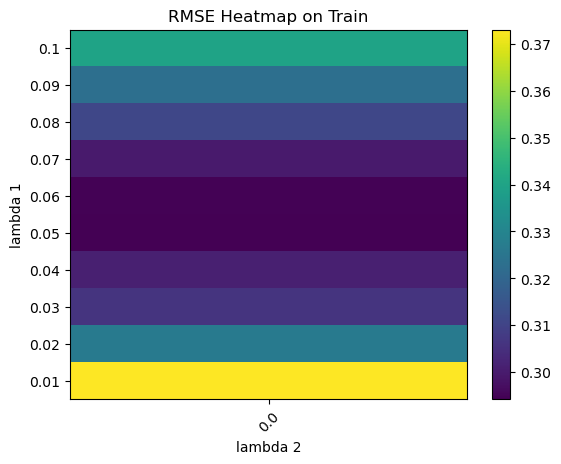

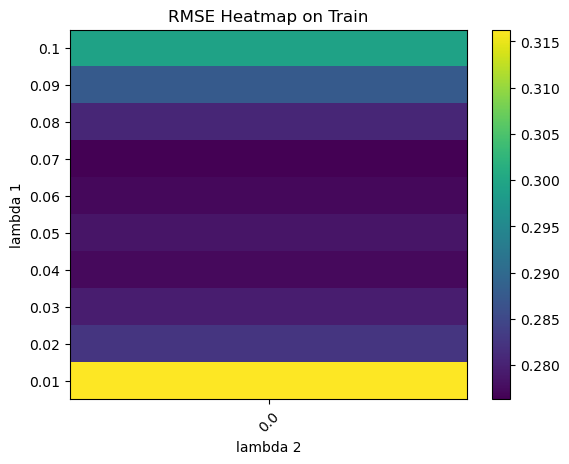

In [8]:
import numpy as np
import matplotlib.pyplot as plt

for i in range(len(trunc_orders)):
    errors_flat = np.array(errors_sig_train[trunc_orders[i]]['rmse'])
    errors_grid = errors_flat.reshape(len(lambda1_vals), len(lambda2_vals))

    # Create heatmap
    plt.figure()
    plt.imshow(errors_grid, origin='lower', aspect='auto')

    plt.xticks(range(len(lambda2_vals)), np.round(lambda2_vals, 4), rotation=45)
    plt.yticks(range(len(lambda1_vals)), np.round(lambda1_vals, 4))

    plt.xlabel("lambda 2")
    plt.ylabel("lambda 1")
    plt.title("RMSE Heatmap on Train")

    plt.colorbar()
    plt.show()


In [9]:
from tabulate import tabulate
errors = []
for d in trunc_orders:
    row = {"model": f"Ridge regression (depth={d})"}
    row['rmse'] = errors_sig_train[d]['rmse'].min()
    errors.append(row)
    min_idx = np.argmin(np.array(errors_sig_train[d]['rmse'])) 
    table_data = [
        ["Trunc order:", d],
        ["Best lambda:", lams_efm[min_idx]],
        ["Train RMSE",  row['rmse']],
        ["Test RMSE",  errors_sig_test[d]['rmse'][min_idx]],
        ["Test MAE",  errors_sig_test[d]['mae'][min_idx]],
        ["Test MAPE",  errors_sig_test[d]['mape'][min_idx]]
    ]
    print(tabulate(table_data, headers=["", "Value"], tablefmt="grid"))

+--------------+---------------------+
|              | Value               |
+==============+=====================+
| Trunc order: | 4                   |
+--------------+---------------------+
| Best lambda: | [5.e-02 1.e-05]     |
+--------------+---------------------+
| Train RMSE   | 0.2942014498153529  |
+--------------+---------------------+
| Test RMSE    | 0.3012232956021841  |
+--------------+---------------------+
| Test MAE     | 0.2207802487577632  |
+--------------+---------------------+
| Test MAPE    | 0.04117617427941246 |
+--------------+---------------------+
+--------------+---------------------+
|              | Value               |
+==============+=====================+
| Trunc order: | 5                   |
+--------------+---------------------+
| Best lambda: | [7.e-02 1.e-05]     |
+--------------+---------------------+
| Train RMSE   | 0.2763069239119623  |
+--------------+---------------------+
| Test RMSE    | 0.28192512866624775 |
+--------------+---------

d:\Anaconda\envs\sigkernel\lib\site-packages\tabulate\__init__.py:108: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  or (len(row) >= 2 and row[1] == SEPARATING_LINE)


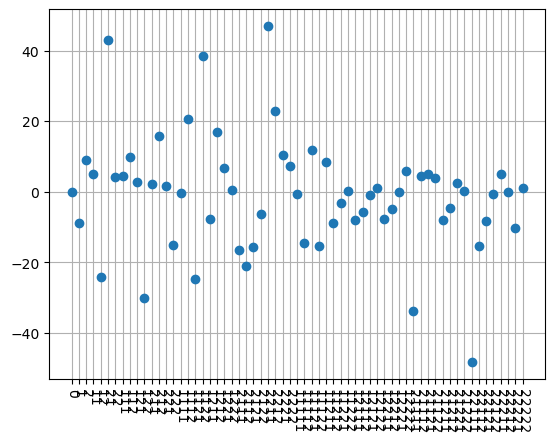

In [11]:
import signature.tensor_algebra as ta


coeff = ta.from_array(array=model[0].coef_, dim=2, trunc=5)
ta.plot_coefficients(coeff, trunc=5)

Without Scaling

In [3]:
from sklearn.metrics import mean_squared_error

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Set parameters and define dictionaries 
total_nb_days = df.size / 48
delay_days = 7
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
trunc_orders = [4,5] #,4,5]
lambdas = [ 0.001] #, 0.01, 0.1, 1, 10, 10**12] #np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2015-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
alpha1 = 0.005
#lams_efm = np.array([jnp.array([ 0.2, 0.03]), jnp.array([ 0.2, 0.03])])# np.linspace(16,20,10) #confiugure lambdas for EFMnp.log(2)/windows #
#lambda1_vals = np.logspace(-2, 0, 5)   # 0.01 → 1
#lambda2_vals = np.logspace(-2, 0, 5)
lambda1_vals =  np.linspace(0.01, 0.1, 10) #np.linspace(0.021, 0.022, 2) #Best rmse around 0.1 for trunc 5 
lambda2_vals = [10e-6]

lams_efm = np.array([
    jnp.array([l1, l2])
    for l1, l2 in itertools.product(lambda1_vals, lambda2_vals)
])
n_lams = lams_efm.shape[0]


METRICS = {
    "rmse": root_mean_squared_error,
    "mae": mean_absolute_error,
    "mape": mean_absolute_percentage_error,
}

models = {
    rf"$\overline{{T}}, {{\overline{{T}}}}^2": "baseline1",
    rf"$T, T^2, \overline{{T}}, {{\overline{{T}}}}^2$": "baseline2",
    rf"$\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$": "baseline3"
}

errors_sig_train = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}
errors_sig_test = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}

metrics = ("rmse", )#, "mae", "mape")

best_penalty = {}
model = {}
# Fit RidgeSig and calculate error metrics 
i=0
for j, d in enumerate(trunc_orders):
    for k, lam in enumerate(lams_efm):
        #print(f'processing for {lam}')
        print('iter:', i)
        i+=1
        result_efm = ridge_signatures(
            covariates=temp,
            target=consumption / 10000,
            window=0, # not needed for EFM
            delay=delay,
            n_train=n_train,
            n_valid=n_train, #No val set
            trunc_order=d,
            penalties=lambdas,
            tune_penalty=False,
            metric="rmse",
            signature_type='efm',
            T=total_nb_days,
            lam = lam, # EFM lambda is taken as constant
            max_window=max(windows), # window taken for the convergence of EFM 
            scale = False
        )
        errors_sig_train[d]["rmse"][k] = result_efm["error_train"]
        errors_sig_train[d]["mae"][k] = METRICS["mae"](result_efm["y_true_train"], result_efm["y_pred_train"])
        errors_sig_train[d]["mape"][k] = METRICS["mape"](result_efm["y_true_train"], result_efm["y_pred_train"]) 
        
        errors_sig_test[d]["rmse"][k] = result_efm["error_test"]
        errors_sig_test[d]["mae"][k] = METRICS["mae"](result_efm["y_true_test"], result_efm["y_pred_test"])
        errors_sig_test[d]["mape"][k] = METRICS["mape"](result_efm["y_true_test"], result_efm["y_pred_test"])
        
        best_penalty[(d,k,"rmse")] = result_efm['best_penalty']
        model[k] = result_efm['model']

iter: 0
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352
Time taken to compute EFM signatures: 4.68 seconds
EFM signatures shape: (68352, 31)
iter: 1
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352


d:\Anaconda\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=4.17189e-27): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Time taken to compute EFM signatures: 2.41 seconds
EFM signatures shape: (68352, 31)
iter: 2
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352


d:\Anaconda\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=3.82979e-27): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Time taken to compute EFM signatures: 2.40 seconds
EFM signatures shape: (68352, 31)
iter: 3
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352


...

d:\Anaconda\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=7.3627e-41): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Time taken to compute EFM signatures: 15.44 seconds
EFM signatures shape: (68352, 63)
iter: 19
t_grid: (1, 70128)
Path shape: (70128, 2)
y size: 68352


d:\Anaconda\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=8.49078e-41): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


Time taken to compute EFM signatures: 14.63 seconds
EFM signatures shape: (68352, 63)


d:\Anaconda\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:215: LinAlgWarning: Ill-conditioned matrix (rcond=8.64548e-41): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T


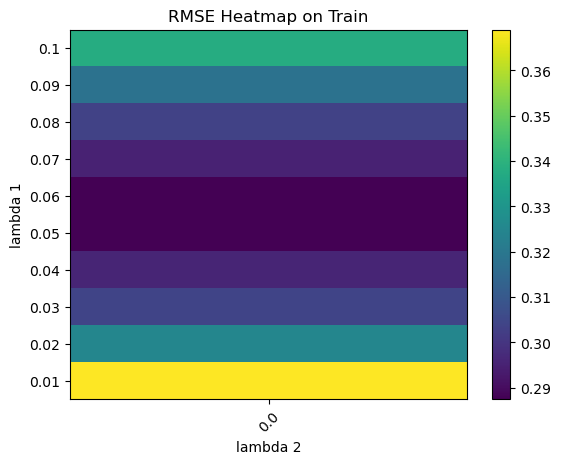

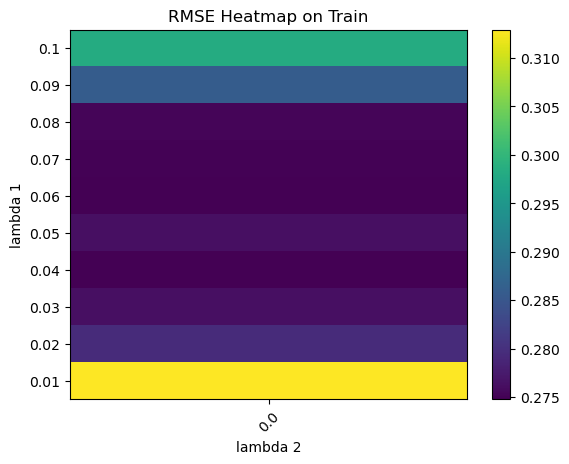

In [4]:
for i in range(len(trunc_orders)):
    errors_flat = np.array(errors_sig_train[trunc_orders[i]]['rmse'])
    errors_grid = errors_flat.reshape(len(lambda1_vals), len(lambda2_vals))

    # Create heatmap
    plt.figure()
    plt.imshow(errors_grid, origin='lower', aspect='auto')

    plt.xticks(range(len(lambda2_vals)), np.round(lambda2_vals, 4), rotation=45)
    plt.yticks(range(len(lambda1_vals)), np.round(lambda1_vals, 4))

    plt.xlabel("lambda 2")
    plt.ylabel("lambda 1")
    plt.title("RMSE Heatmap on Train")

    plt.colorbar()
    plt.show()


In [5]:
errors = []
for d in trunc_orders:
    row = {"model": f"Ridge regression (depth={d})"}
    row['rmse'] = errors_sig_train[d]['rmse'].min()
    errors.append(row)
    min_idx = np.argmin(np.array(errors_sig_train[d]['rmse'])) 
    table_data = [
        ["Trunc order:", d],
        ["Best lambda:", lams_efm[min_idx]],
        ["Train RMSE",  row['rmse']],
        ["Test RMSE",  errors_sig_test[d]['rmse'][min_idx]],
        ["Test MAE",  errors_sig_test[d]['mae'][min_idx]],
        ["Test MAPE",  errors_sig_test[d]['mape'][min_idx]]
    ]
    print(tabulate(table_data, headers=["", "Value"], tablefmt="grid"))

+--------------+---------------------+
|              | Value               |
+==============+=====================+
| Trunc order: | 4                   |
+--------------+---------------------+
| Best lambda: | [5.e-02 1.e-05]     |
+--------------+---------------------+
| Train RMSE   | 0.28745606379612704 |
+--------------+---------------------+
| Test RMSE    | 0.29227890547898705 |
+--------------+---------------------+
| Test MAE     | 0.20794039746080697 |
+--------------+---------------------+
| Test MAPE    | 0.03848347832782254 |
+--------------+---------------------+
+--------------+---------------------+
|              | Value               |
+==============+=====================+
| Trunc order: | 5                   |
+--------------+---------------------+
| Best lambda: | [4.e-02 1.e-05]     |
+--------------+---------------------+
| Train RMSE   | 0.2747825593305444  |
+--------------+---------------------+
| Test RMSE    | 0.33605394906845726 |
+--------------+---------

d:\Anaconda\envs\sigkernel\lib\site-packages\tabulate\__init__.py:108: FutureWarning: elementwise comparison failed; returning scalar instead, but in the future will perform elementwise comparison
  or (len(row) >= 2 and row[1] == SEPARATING_LINE)


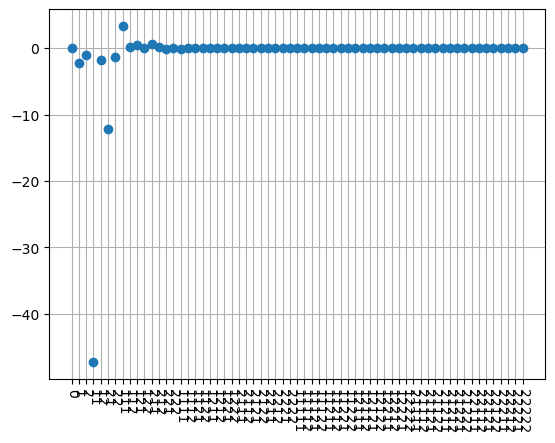

In [6]:
import signature.tensor_algebra as ta

coeff = ta.from_array(array=model[0].coef_, dim=2, trunc=5)
ta.plot_coefficients(coeff, trunc=5)

Doubling the covariate

In [5]:

def root_mean_squared_error(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

# Set parameters and define dictionaries s
total_nb_days = df.size / 48
delay_days = 7
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
trunc_orders = [5] #,4,5]
lambdas = [ 0.001] #, 0.01, 0.1, 1, 10, 10**12] #np.logspace(-1, 2, 20)
n_train = (df["DateTime"] < "2015-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
alpha1 = 0.005
#lams_efm = np.array([jnp.array([ 0.2, 0.03]), jnp.array([ 0.2, 0.03])])# np.linspace(16,20,10) #confiugure lambdas for EFMnp.log(2)/windows #
#lambda1_vals = np.logspace(-2, 0, 5)   # 0.01 → 1
#lambda2_vals = np.logspace(-2, 0, 5)
lambda1_vals =  np.linspace(0.001, 1, 2) #np.linspace(0.021, 0.022, 2) #Best rmse around 0.1 for trunc 5
lambda2_vals = np.linspace(0.001, 1, 2)
lambda3_vals = np.linspace(0.001, 1, 2)

lams_efm = np.array([
    jnp.array([l1, l2, 0])
    for l1, l2 in itertools.product(lambda1_vals, lambda2_vals)
])
n_lams = lams_efm.shape[0]


METRICS = {
    "rmse": root_mean_squared_error,
    "mae": mean_absolute_error,
    "mape": mean_absolute_percentage_error,
}

models = {
    rf"$\overline{{T}}, {{\overline{{T}}}}^2": "baseline1",
    rf"$T, T^2, \overline{{T}}, {{\overline{{T}}}}^2$": "baseline2",
    rf"$\left(T, T^2, \overline{{T}}, \overline{{T}}^2, Y_{{t-7\text{{ days}}}} \right)$": "baseline3"
}

errors_sig_train = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}
errors_sig_test = {
    d: {m: np.empty(n_lams) for m in METRICS.keys()}
    for d in trunc_orders
}

metrics = ("rmse", )#, "mae", "mape")

best_penalty = {}
model = {}
# Fit RidgeSig and calculate error metrics 
i=0
for j, d in enumerate(trunc_orders):
    for k, lam in enumerate(lams_efm):
        #print(f'processing for {lam}')
        print('iter:', i)
        i+=1
        result_efm = ridge_signatures(
            covariates=temp2,
            target=consumption / 10000,
            window=0, # not needed for EFM
            delay=delay,
            n_train=n_train,
            n_valid=n_train, #No val set
            trunc_order=d,
            penalties=lambdas,
            tune_penalty=False,
            metric="rmse",
            signature_type='efm',
            T=total_nb_days,
            lam = lam, # EFM lambda is taken as constant
            max_window=max(windows), # window taken for the convergence of EFM 
            scale = True
        )
        errors_sig_train[d]["rmse"][k] = result_efm["error_train"]
        errors_sig_train[d]["mae"][k] = METRICS["mae"](result_efm["y_true_train"], result_efm["y_pred_train"])
        errors_sig_train[d]["mape"][k] = METRICS["mape"](result_efm["y_true_train"], result_efm["y_pred_train"]) 
        
        errors_sig_test[d]["rmse"][k] = result_efm["error_test"]
        errors_sig_test[d]["mae"][k] = METRICS["mae"](result_efm["y_true_test"], result_efm["y_pred_test"])
        errors_sig_test[d]["mape"][k] = METRICS["mape"](result_efm["y_true_test"], result_efm["y_pred_test"])
        
        best_penalty[(d,k,"rmse")] = result_efm['best_penalty']
        model[k] = result_efm['model']

iter: 0
sim path: (2, 70128)
t_grid: (1, 70128)
Path shape: (70128, 3)
y size: 68352
Time taken to compute EFM signatures: 354.62 seconds
EFM signatures shape: (68352, 364)
iter: 1
sim path: (2, 70128)
t_grid: (1, 70128)
Path shape: (70128, 3)
y size: 68352
Time taken to compute EFM signatures: 334.56 seconds
EFM signatures shape: (68352, 364)
iter: 2
sim path: (2, 70128)
t_grid: (1, 70128)
Path shape: (70128, 3)
y size: 68352
Time taken to compute EFM signatures: 302.65 seconds
EFM signatures shape: (68352, 364)
iter: 3
sim path: (2, 70128)
t_grid: (1, 70128)
Path shape: (70128, 3)
y size: 68352
Time taken to compute EFM signatures: 296.09 seconds
EFM signatures shape: (68352, 364)


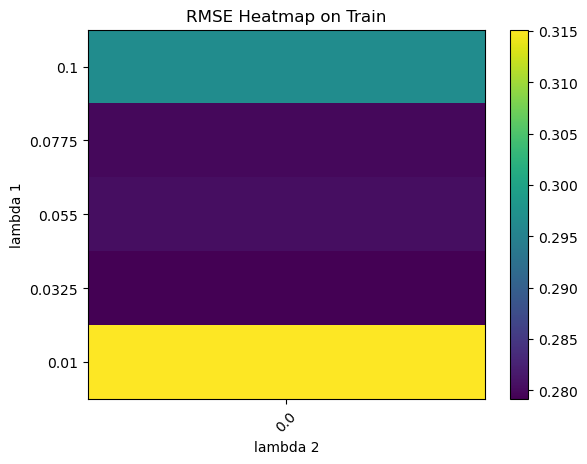

In [10]:
for i in range(len(trunc_orders)):
    errors_flat = np.array(errors_sig_train[trunc_orders[i]]['rmse'])
    errors_grid = errors_flat.reshape(len(lambda1_vals), len(lambda2_vals))

    # Create heatmap
    plt.figure()
    plt.imshow(errors_grid, origin='lower', aspect='auto')

    plt.xticks(range(len(lambda2_vals)), np.round(lambda2_vals, 4), rotation=45)
    plt.yticks(range(len(lambda1_vals)), np.round(lambda1_vals, 4))

    plt.xlabel("lambda 2")
    plt.ylabel("lambda 1")
    plt.title("RMSE Heatmap on Train")

    plt.colorbar()
    plt.show()
